# Case 3 — Part 1: Iterative Machine Learning Model Training & Latency Prediction

This notebook is dedicated to the **iterative exploration, training, hyperparameter tuning, and validation** of Machine Learning models used to predict container latency under real-world workloads.

---

### Objectives
1. **Exploratory Data Analysis (EDA):** Understand how CPU allocation, RAM, request rate (RPS), and payload complexity impact container latency.
2. **Target Transformation:** Evaluate raw vs. $\log(1 + W)$ transformations to handle heavy-tailed queue latency distributions.
3. **Iterative Model Benchmarking:**
   - **Model 1: Ridge Regression (Linear Baseline)** — analyze linear weights and limitations.
   - **Model 2: Random Forest Regressor (Ensemble)** — capture non-linear step responses and feature importances.
   - **Model 3: Multi-Layer Perceptron (MLP Neural Network)** — explore architectures (`(32,)`, `(64, 32)`, `(128, 64, 32)`), loss curves, and convergence.
4. **Validation & Parity Analysis:** 5-Fold Cross Validation, parity plots, and error residuals.
5. **Artifact Export:** Save the trained surrogate models for downstream container resource optimization.


In [1]:
import os
ASSETS_DIR = os.path.join("assets", "part3") if os.path.exists("assets") else os.path.join("..", "assets", "part3")
os.makedirs(ASSETS_DIR, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from container_ml_model import (
    load_and_preprocess_dataset,
    save_artifacts,
    FEATURE_COLS,
    DEFAULT_MODELS_DIR,
)

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

## 1. Exploratory Data Analysis (EDA)

We load the telemetry dataset (`data/container_performance_web1.csv`) gathered from benchmark experiments on containerized Nginx web servers running on Linux.


In [2]:
clean_data, X, y = load_and_preprocess_dataset()
print(f"Dataset Shape: {clean_data.shape}")
print(f"Features: {list(X.columns)}")
clean_data.describe().T


Dataset Shape: (1598, 5)
Features: ['cpu_mcpu', 'ram_mb', 'rps', 'is_heavy_payload']


,count,mean,std,min,25%,50%,75%,max
cpu_mcpu,1598.0,549.937422,287.143636,100.00,300.0000,550.0000,800.0000,1000.000
ram_mb,1598.0,240.220275,171.628851,64.00,128.0000,256.0000,448.0000,512.000
rps,1598.0,3139.694675,3427.605315,0.35,2.9125,829.6450,7368.8175,7683.180
is_heavy_payload,1598.0,0.500000,0.500157,0.00,0.0000,0.5000,1.0000,1.000
latency_ms,1598.0,338.588081,616.074148,0.13,0.1360,97.5415,343.3395,2817.843


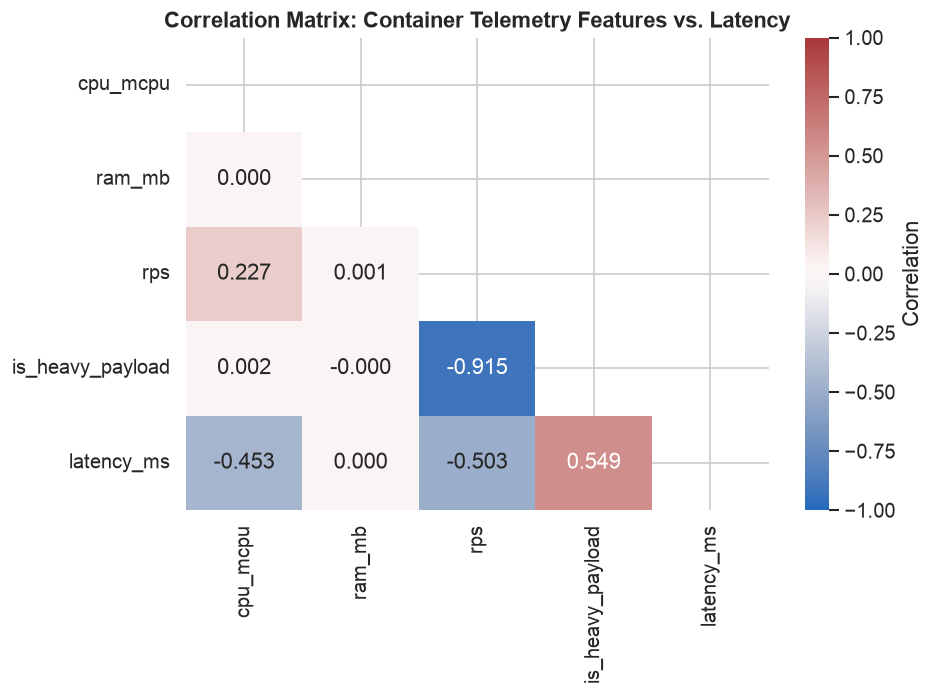

In [3]:
plt.figure(figsize=(8, 6))
corr = clean_data.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1, cbar_kws={"label": "Correlation"})
plt.title("Correlation Matrix: Container Telemetry Features vs. Latency", fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "01_correlation_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

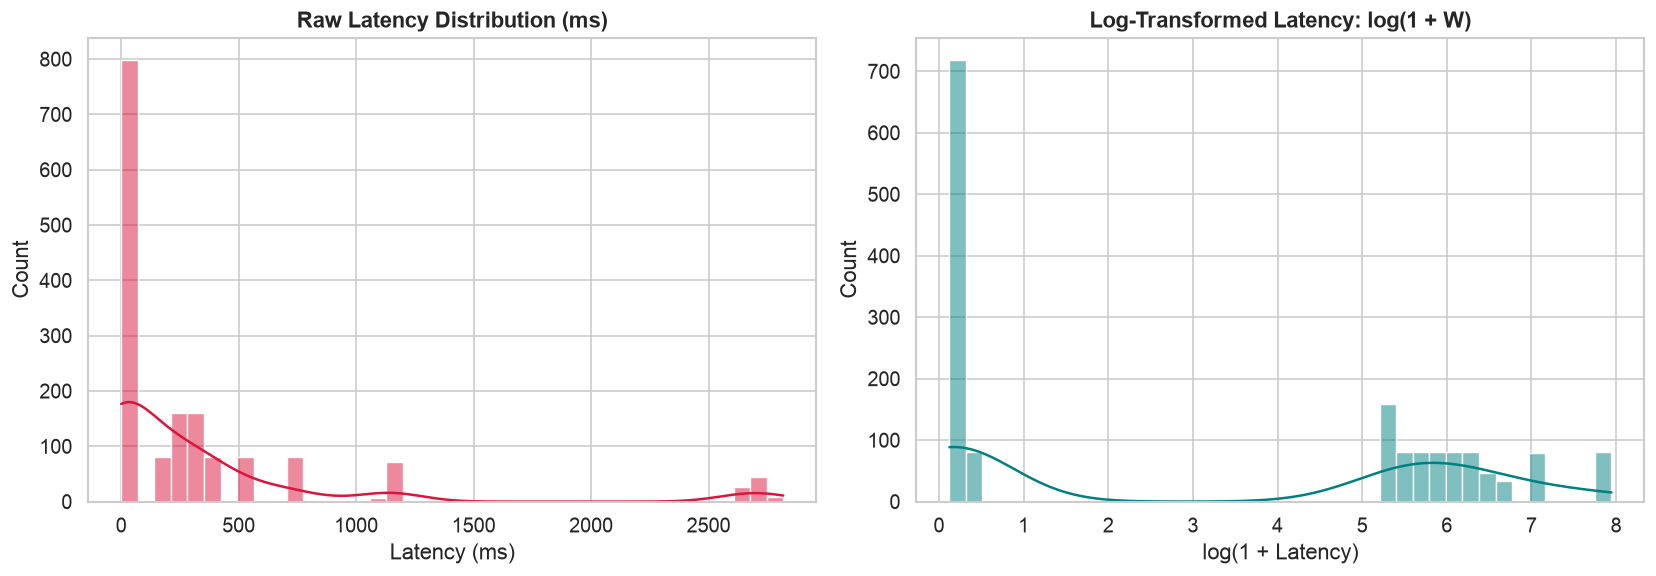

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw vs Log Latency Distribution
sns.histplot(clean_data["latency_ms"], bins=40, kde=True, ax=axes[0], color="crimson")
axes[0].set_title("Raw Latency Distribution (ms)", fontweight="bold")
axes[0].set_xlabel("Latency (ms)")

sns.histplot(np.log1p(clean_data["latency_ms"]), bins=40, kde=True, ax=axes[1], color="teal")
axes[1].set_title("Log-Transformed Latency: log(1 + W)", fontweight="bold")
axes[1].set_xlabel("log(1 + Latency)")

plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "02_latency_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

## 2. Feature Preprocessing & Train/Test Split

Because container response times span orders of magnitude ($0.1\text{ ms}$ up to $2800\text{ ms}$), modeling target in log-space:
$$y = \log(1 + W)$$
stabilizes variance and prevents extreme saturation points from dominating the mean squared error.

Input features are standardized using `StandardScaler` to ensure zero mean and unit variance.


In [5]:
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, np.log1p(y), test_size=0.2, random_state=42
)
y_test_raw = y.loc[y_test_log.index].values

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=FEATURE_COLS)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=FEATURE_COLS)

print(f"Training samples: {len(X_train)} | Test samples: {len(X_test)}")


Training samples: 1278 | Test samples: 320


## 3. Iterative Experimentation — Model 1: Ridge Regression (Linear Baseline)

We test Ridge regression across multiple regularization strengths $\alpha \in [10^{-3}, 10^3]$.


Optimal Alpha: 0.1207
Ridge Test Metrics -> R²: 0.6351 | MAE: 126.72 ms | RMSE: 389.70 ms


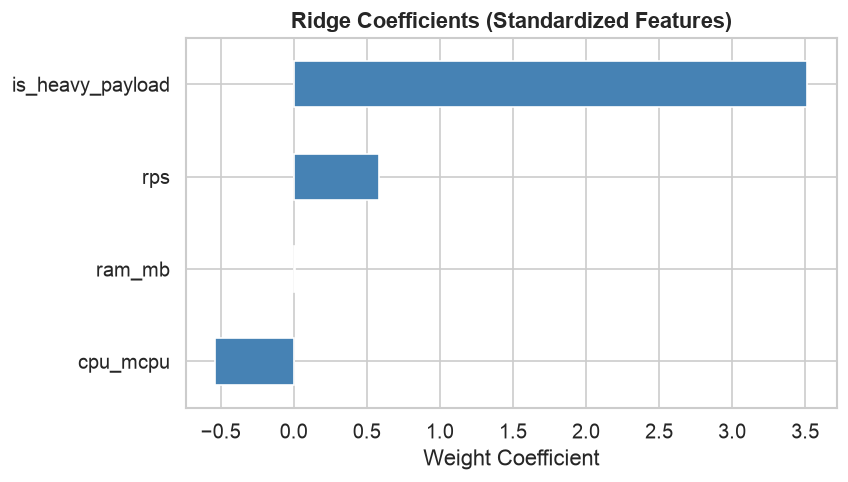

In [6]:
alphas = np.logspace(-3, 3, 50)
ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_train_s, y_train_log)

print(f"Optimal Alpha: {ridge_cv.alpha_:.4f}")

# Evaluate Ridge
ridge_preds_log = ridge_cv.predict(X_test_s)
ridge_preds_raw = np.clip(np.expm1(ridge_preds_log), 0.01, None)

r2_ridge = r2_score(y_test_raw, ridge_preds_raw)
mae_ridge = mean_absolute_error(y_test_raw, ridge_preds_raw)
rmse_ridge = np.sqrt(mean_squared_error(y_test_raw, ridge_preds_raw))

print(f"Ridge Test Metrics -> R²: {r2_ridge:.4f} | MAE: {mae_ridge:.2f} ms | RMSE: {rmse_ridge:.2f} ms")

# Inspect feature weights
coef_df = pd.Series(ridge_cv.coef_, index=FEATURE_COLS).sort_values()
plt.figure(figsize=(7, 4))
coef_df.plot(kind="barh", color="steelblue")
plt.title("Ridge Coefficients (Standardized Features)", fontweight="bold")
plt.xlabel("Weight Coefficient")
plt.savefig(os.path.join(ASSETS_DIR, "03_ridge_coefficients.png"), dpi=150, bbox_inches="tight")
plt.show()

## 4. Iterative Experimentation — Model 2: Random Forest Regressor

We analyze Random Forest performance under different tree counts ($n \in [10, 50, 100, 200]$) and examine feature importances.


,n_estimators,R2,MAE_ms,RMSE_ms
0,10,0.999950,1.171852,4.549175
1,30,0.999948,1.177618,4.634254
2,50,0.999949,1.181454,4.609519
3,100,0.999950,1.168940,4.551929
4,150,0.999951,1.162147,4.505756


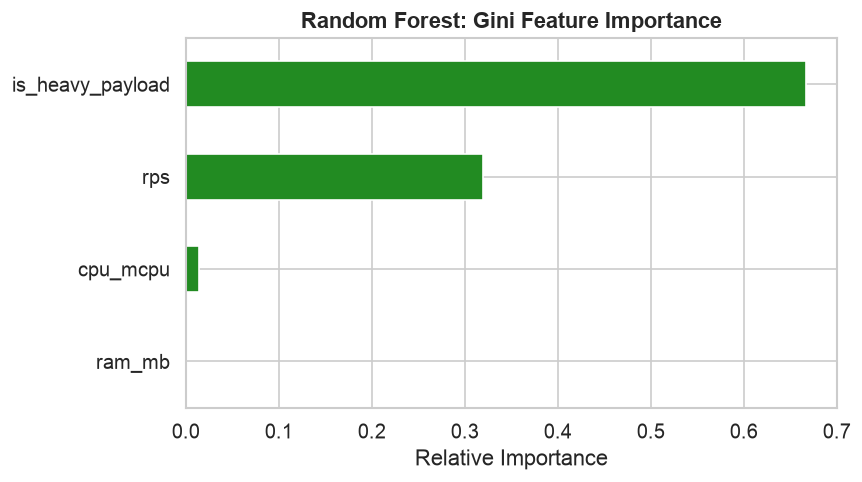

In [7]:
n_trees_list = [10, 30, 50, 100, 150]
rf_results = []

for n_trees in n_trees_list:
    rf = RandomForestRegressor(n_estimators=n_trees, random_state=42)
    rf.fit(X_train_s, y_train_log)
    preds = np.clip(np.expm1(rf.predict(X_test_s)), 0.01, None)
    rf_results.append({
        "n_estimators": n_trees,
        "R2": r2_score(y_test_raw, preds),
        "MAE_ms": mean_absolute_error(y_test_raw, preds),
        "RMSE_ms": np.sqrt(mean_squared_error(y_test_raw, preds)),
    })

rf_df = pd.DataFrame(rf_results)
display(rf_df)

best_rf = RandomForestRegressor(n_estimators=100, random_state=42)
best_rf.fit(X_train_s, y_train_log)

# Plot Feature Importances
importances = pd.Series(best_rf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)
plt.figure(figsize=(7, 4))
importances.plot(kind="barh", color="forestgreen")
plt.title("Random Forest: Gini Feature Importance", fontweight="bold")
plt.xlabel("Relative Importance")
plt.savefig(os.path.join(ASSETS_DIR, "04_rf_feature_importances.png"), dpi=150, bbox_inches="tight")
plt.show()

## 5. Iterative Experimentation — Model 3: Multi-Layer Perceptron (MLP) Neural Network

Here, we explore three neural network architectures:
1. **Shallow MLP:** Hidden layer `(32,)`
2. **Intermediate MLP:** Hidden layers `(64, 32)`
3. **Deep MLP:** Hidden layers `(128, 64, 32)`

We also plot the **loss convergence curves** during training iterations.


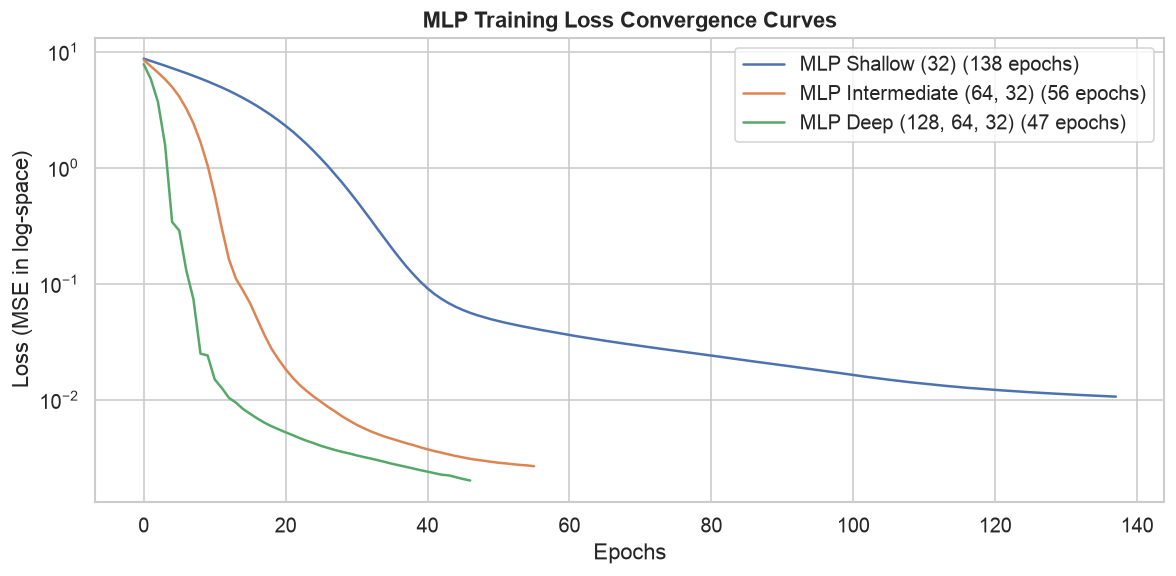

,Architecture,R2,MAE (ms),RMSE (ms),Iterations
0,MLP Shallow (32),0.882175,76.456304,221.438715,138
1,"MLP Intermediate (64, 32)",0.953556,50.433379,139.026990,56
2,"MLP Deep (128, 64, 32)",0.965583,42.623468,119.680180,47


In [8]:
architectures = {
    "MLP Shallow (32)": (32,),
    "MLP Intermediate (64, 32)": (64, 32),
    "MLP Deep (128, 64, 32)": (128, 64, 32),
}

mlp_models = {}
mlp_metrics = []

plt.figure(figsize=(10, 5))

for name, arch in architectures.items():
    mlp = MLPRegressor(
        hidden_layer_sizes=arch,
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=42,
    )
    mlp.fit(X_train_s, y_train_log)
    mlp_models[name] = mlp
    
    preds = np.clip(np.expm1(mlp.predict(X_test_s)), 0.01, None)
    mlp_metrics.append({
        "Architecture": name,
        "R2": r2_score(y_test_raw, preds),
        "MAE (ms)": mean_absolute_error(y_test_raw, preds),
        "RMSE (ms)": np.sqrt(mean_squared_error(y_test_raw, preds)),
        "Iterations": mlp.n_iter_,
    })
    
    plt.plot(mlp.loss_curve_, label=f"{name} ({mlp.n_iter_} epochs)")

plt.title("MLP Training Loss Convergence Curves", fontweight="bold")
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE in log-space)")
plt.yscale("log")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "05_mlp_loss_convergence.png"), dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(mlp_metrics)

## 6. Comprehensive Model Comparison & Parity Analysis

We compare the three representative models:
- **Ridge (alpha=optimal)**
- **Random Forest (100 trees)**
- **MLP (64, 32)**


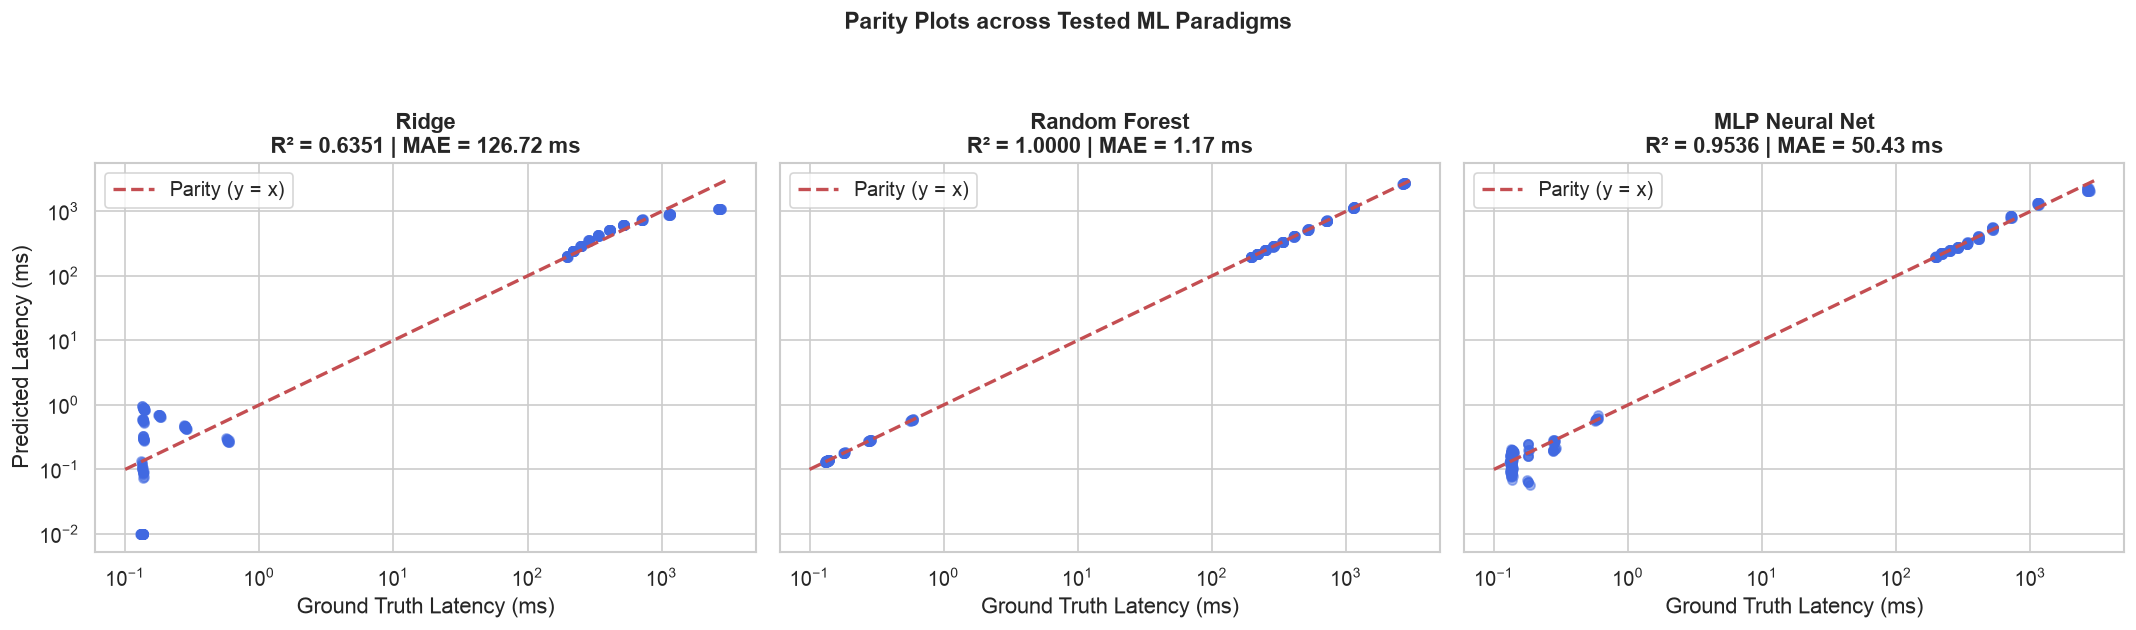

In [9]:
final_models = {
    "Ridge": ridge_cv,
    "Random Forest": best_rf,
    "MLP Neural Net": mlp_models["MLP Intermediate (64, 32)"],
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True, sharex=True)

for ax, (name, model) in zip(axes, final_models.items()):
    preds = np.clip(np.expm1(model.predict(X_test_s)), 0.01, None)
    r2 = r2_score(y_test_raw, preds)
    mae = mean_absolute_error(y_test_raw, preds)
    
    ax.scatter(y_test_raw, preds, alpha=0.5, s=30, color="royalblue")
    ax.plot([0.1, 3000], [0.1, 3000], "r--", lw=2, label="Parity (y = x)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{name}\nR² = {r2:.4f} | MAE = {mae:.2f} ms", fontweight="bold")
    ax.set_xlabel("Ground Truth Latency (ms)")
    if ax == axes[0]:
        ax.set_ylabel("Predicted Latency (ms)")
    ax.legend()

plt.suptitle("Parity Plots across Tested ML Paradigms", fontsize=14, y=1.05, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(ASSETS_DIR, "06_models_actual_vs_predicted.png"), dpi=150, bbox_inches="tight")
plt.show()

## 7. Artifact Persistence for Container Optimization

We persist the best trained models, scaler, and performance metrics to `models/` so that the **Optimization Notebook** (`container_ml_analysis.ipynb`) and the optimization script (`container_ml_model.py`) can load them directly.


In [10]:
models_to_export = {
    "ridge": ridge_cv,
    "random_forest": best_rf,
    "mlp": mlp_models["MLP Intermediate (64, 32)"],
}

metrics_to_export = {}
for name, model in models_to_export.items():
    preds = np.clip(np.expm1(model.predict(X_test_s)), 0.01, None)
    metrics_to_export[name] = {
        "r2": float(r2_score(y_test_raw, preds)),
        "mae_ms": float(mean_absolute_error(y_test_raw, preds)),
        "rmse_ms": float(np.sqrt(mean_squared_error(y_test_raw, preds))),
    }

save_artifacts(models=models_to_export, scaler=scaler, metrics=metrics_to_export)
print(f"Artifacts successfully saved to: {DEFAULT_MODELS_DIR}")


Artifacts successfully saved to: /Users/carloshkayser/Projects/optimization-in-cs/system/models
